In [5]:
import torch

# Device configuration
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

if device == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    torch.backends.cudnn.benchmark = True

Using device: cuda
GPU Name: Tesla T4
VRAM Available: 15.6 GB


In [6]:
!pip install kagglehub

In [7]:
import kagglehub
import shutil
from pathlib import Path

path = kagglehub.dataset_download("anshulmehtakaggl/wildlife-animals-images")

Using Colab cache for faster access to the 'wildlife-animals-images' dataset.


In [8]:
data_path = Path("data/wildlife-images")

if not data_path.exists():
    shutil.copytree(path, data_path)

In [9]:
import shutil
import re
from pathlib import Path

raw_dir = Path("data/wildlife-images")
clean_dir = Path("data/clean-wildlife-images")
TARGET_SIZE = "512"

clean_dir.mkdir(parents=True, exist_ok=True)

for folder in raw_dir.iterdir():
    if folder.is_dir() and TARGET_SIZE in folder.name:
        animal_name = re.sub(r"[-_\s]*(resize|resized)?[-_\s]*\d+.*$", "", folder.name, flags=re.IGNORECASE).strip()

        target_path = clean_dir / animal_name
        if not target_path.exists():
            shutil.copytree(folder, target_path)
            print(f"Mapped: {folder.name}  -->  {target_path}")

Mapped: fox-resize-512  -->  data/clean-wildlife-images/fox
Mapped: tiger-resize-512  -->  data/clean-wildlife-images/tiger
Mapped: wolf-resize-512  -->  data/clean-wildlife-images/wolf
Mapped: lion-resize-512  -->  data/clean-wildlife-images/lion
Mapped: cheetah-resize-512  -->  data/clean-wildlife-images/cheetah
Mapped: hyena-resize-512  -->  data/clean-wildlife-images/hyena


In [10]:
from torchvision import transforms

IMG_SIZE = (256, 256)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(size=(128, 128), scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15))
])

test_transform = transforms.Compose([
    transforms.Resize(size=(128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

In [11]:
import os
from PIL import Image

dataset_dir = "data/clean-wildlife-images"

corrupted_files = []

for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        file_path = os.path.join(root, file)
        if file.startswith('.'):
            continue

        try:
            with Image.open(file_path) as img:
                img.verify()
        except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
            print(f"Corrupted file found: {file_path}")
            corrupted_files.append(file_path)

if corrupted_files:
    delete = input(f"\nFound {len(corrupted_files)} broken file(s). Delete them? (y/n): ")
    if delete.lower() == 'y':
        for f in corrupted_files:
            os.remove(f)
        print("Corrupted files removed successfully.")
else:
    print("All images verified successfully!")

Corrupted file found: data/clean-wildlife-images/cheetah/resize-512/00000244_512resized.png
Corrupted file found: data/clean-wildlife-images/hyena/resize-512/00000224_512resized.png

Found 2 broken file(s). Delete them? (y/n): Y
Corrupted files removed successfully.


In [12]:
import os
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

ROOT_DIR = "data/clean-wildlife-images"
BATCH_SIZE = 32

train_dataset_full = datasets.ImageFolder(root=ROOT_DIR, transform=train_transform)
test_dataset_full = datasets.ImageFolder(root=ROOT_DIR, transform=test_transform)

class_names = train_dataset_full.classes
print(f"Found {len(class_names)} animal classes: {class_names}")
print(f"Total images: {len(train_dataset_full)}")

num_total = len(train_dataset_full)
num_train = int(0.8 * num_total)

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(num_total, generator=generator).tolist()

train_data = Subset(train_dataset_full, indices[:num_train])
test_data = Subset(test_dataset_full, indices[num_train:])

NUM_WORKERS = os.cpu_count() or 2

train_dataloader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True
)
test_dataloader = DataLoader(
    test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True
)

images, labels = next(iter(train_dataloader))
print(f"Batch image shape: {images.shape}")
print(f"Batch label shape: {labels.shape}")

Found 6 animal classes: ['cheetah', 'fox', 'hyena', 'lion', 'tiger', 'wolf']
Total images: 1723
Batch image shape: torch.Size([32, 3, 128, 128])
Batch label shape: torch.Size([32])


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


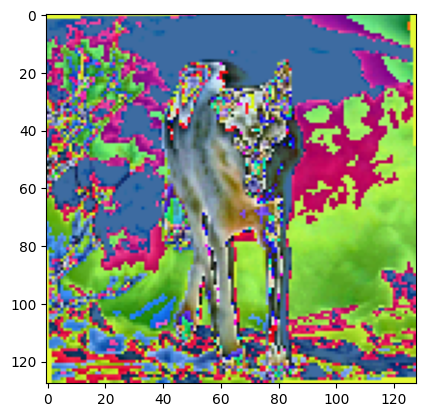

In [13]:
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

images, labels = next(iter(train_dataloader))
sample_tensor = images[0]

to_pil = transforms.ToPILImage()
sample_img = to_pil(sample_tensor)
plt.imshow(sample_img)

In [14]:
from torch import nn

class AnimalModel(nn.Module):
    def __init__(self, input_features, hidden_units, output_features):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_features,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(hidden_units * 16, output_features)
        )

    def forward(self, x):
        return self.classifier(self.conv_block_3(self.conv_block_2(self.conv_block_1(x))))

In [15]:
def train_model(model, loss_fn, optimiser, accuracy_fn, dataloader, device=device):
    train_acc, train_loss = 0, 0
    model.to(device)
    model.train()

    for X, y in dataloader:
        X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)

        optimiser.zero_grad()
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        loss.backward()
        optimiser.step()

        acc = accuracy_fn(y, y_pred.argmax(dim=1))
        train_acc += acc

    train_acc /= len(dataloader)
    train_loss /= len(dataloader)
    print(f"Train acc: {train_acc:.2f}% | Train loss: {train_loss:.4f}")

def test_model(model, loss_fn, accuracy_fn, dataloader, device=device):
    test_acc, test_loss = 0, 0
    model.to(device)
    model.eval()

    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)

            y_pred = model(X)
            loss = loss_fn(y_pred, y)
            acc = accuracy_fn(y, y_pred.argmax(dim=1))
            test_acc += acc
            test_loss += loss.item()

        test_acc /= len(dataloader)
        test_loss /= len(dataloader)
    print(f"Test acc: {test_acc:.2f}% | Test loss: {test_loss:.4f}")

In [16]:
class_names = train_dataset_full.classes
print(f"Classes: {class_names}")
train_data_features, train_data_labels = next(iter(train_dataloader))
print(f"Feature shape: {train_data_features.shape}, Label shape: {train_data_labels.shape}")

(torch.Size([32, 3, 128, 128]), torch.Size([32]))

In [17]:
model = AnimalModel(3, 128, len(class_names))
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimiser = torch.optim.Adam(params=model.parameters(), lr=0.001)

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [18]:
import torch
from tqdm.auto import tqdm
import warnings

torch.cuda.empty_cache()
warnings.filterwarnings("ignore", message="Palette images with Transparency")

epochs = 100
for epoch in tqdm(range(epochs)):
    train_model(model, loss_fn, optimiser, accuracy_fn, train_dataloader)
    test_model(model, loss_fn, accuracy_fn, test_dataloader)
    print(f'Epoch: {epoch}')

  0%|          | 0/100 [00:00<?, ?it/s]

Train acc: 18.96% | Train loss: 1.7873
Test acc: 16.43% | Test loss: 1.7991
Epoch: 0
Train acc: 26.21% | Train loss: 1.7347
Test acc: 29.82% | Test loss: 1.7171
Epoch: 1
Train acc: 34.80% | Train loss: 1.5956
Test acc: 40.28% | Test loss: 1.4791
Epoch: 2
Train acc: 39.99% | Train loss: 1.4934
Test acc: 44.62% | Test loss: 1.5173
Epoch: 3
Train acc: 42.83% | Train loss: 1.4942
Test acc: 41.50% | Test loss: 1.4575
Epoch: 4
Train acc: 47.44% | Train loss: 1.4384
Test acc: 46.33% | Test loss: 1.5680
Epoch: 5
Train acc: 44.46% | Train loss: 1.4702
Test acc: 53.95% | Test loss: 1.3402
Epoch: 6
Train acc: 55.04% | Train loss: 1.3081
Test acc: 52.94% | Test loss: 1.3505
Epoch: 7
Train acc: 56.32% | Train loss: 1.3088
Test acc: 59.48% | Test loss: 1.2626
Epoch: 8
Train acc: 59.59% | Train loss: 1.2691
Test acc: 51.73% | Test loss: 1.4333
Epoch: 9
Train acc: 59.09% | Train loss: 1.2364
Test acc: 62.48% | Test loss: 1.1779
Epoch: 10
Train acc: 64.77% | Train loss: 1.1476
Test acc: 66.90% | Test l

In [20]:
def make_predictions(model, data, device=device):
    pred_probs = []
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for sample in data:
            sample = torch.unsqueeze(sample, dim=0).to(device)
            pred_logits = model(sample)
            pred_prob = torch.softmax(pred_logits.squeeze(), dim=0)
            pred_probs.append(pred_prob)

    return torch.stack(pred_probs).cpu()

import random
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

pred_probs = make_predictions(model=model, data=test_samples)
pred_classes = pred_probs.argmax(dim=1)
print(f"Predicted classes: {pred_classes.tolist()}")
print(f"True labels:      {test_labels}")

Predicted classes: [0, 1, 0, 5, 4, 0, 3, 1, 3]
True labels:      [0, 1, 0, 5, 4, 0, 3, 1, 3]


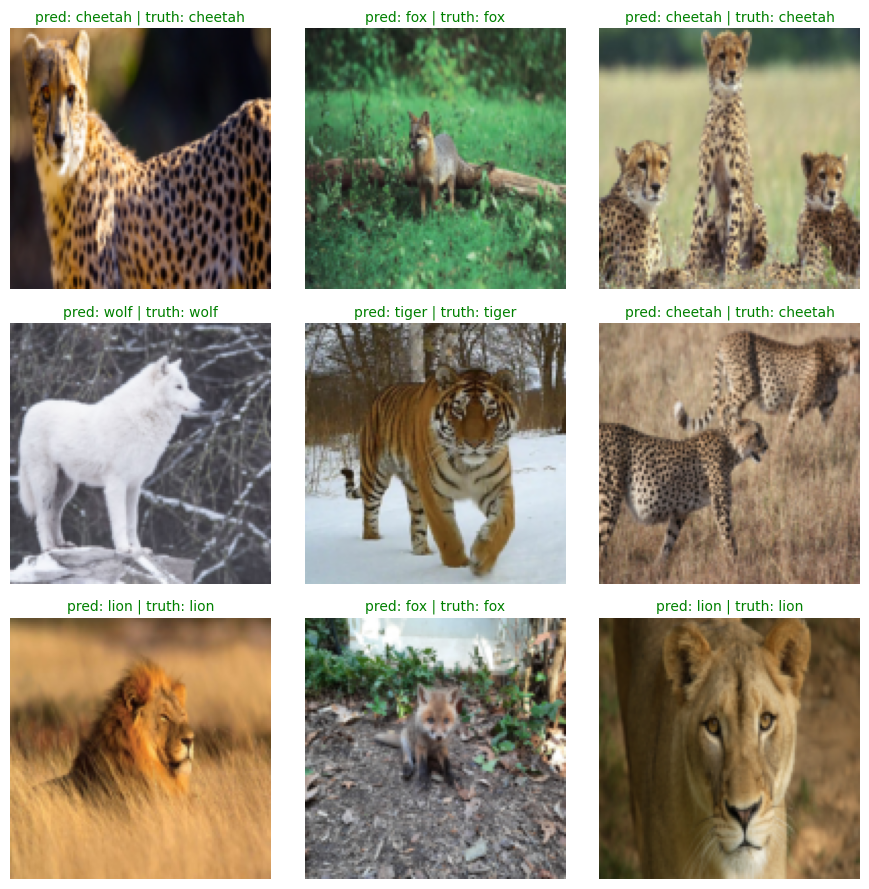

In [21]:
import torch
import matplotlib.pyplot as plt

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)

plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3

for i, sample in enumerate(test_samples):
    plt.subplot(nrows, ncols, i + 1)

    unnorm_sample = (sample.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    plt.imshow(unnorm_sample.permute(1, 2, 0))

    pred_label = class_names[pred_classes[i]]
    truth_label = class_names[test_labels[i]]
    title_text = f'pred: {pred_label} | truth: {truth_label}'

    if pred_label == truth_label:
        plt.title(title_text, fontsize=10, c='g')
    else:
        plt.title(title_text, fontsize=10, c='r')

    plt.axis(False)

plt.tight_layout()

In [23]:
y_preds = []
model.eval()
with torch.inference_mode():
    for X, y in tqdm(test_dataloader, desc="Making predictions..."):
        y_logits = model(X.to(device))
        y_pred = torch.softmax(y_logits.squeeze(), dim=0).argmax(dim=1)
        y_preds.append(y_pred)

y_pred_tensor = torch.cat(y_preds)

Making predictions....:   0%|          | 0/11 [00:00<?, ?it/s]

[tensor([4, 0, 0, 4, 4, 5, 2, 2, 4, 2, 3, 1, 1, 0, 4, 0, 5, 0, 0, 0, 3, 4, 4, 5,
        1, 5, 3, 1, 4, 0, 3, 3], device='cuda:0'), tensor([3, 3, 5, 0, 0, 0, 0, 5, 2, 0, 4, 0, 1, 2, 5, 1, 5, 3, 1, 5, 4, 1, 2, 2,
        3, 4, 5, 4, 1, 3, 4, 1], device='cuda:0'), tensor([5, 3, 2, 5, 2, 0, 3, 0, 0, 2, 0, 1, 4, 3, 2, 3, 2, 4, 5, 0, 3, 1, 1, 0,
        4, 4, 5, 4, 4, 0, 3, 4], device='cuda:0'), tensor([1, 3, 1, 0, 2, 4, 5, 0, 1, 5, 4, 1, 4, 4, 4, 3, 3, 3, 2, 0, 5, 2, 5, 2,
        1, 3, 4, 2, 2, 5, 2, 5], device='cuda:0'), tensor([0, 5, 1, 5, 3, 0, 3, 1, 4, 1, 2, 4, 0, 1, 3, 5, 4, 3, 3, 0, 2, 2, 0, 3,
        1, 3, 4, 1, 4, 0, 0, 3], device='cuda:0'), tensor([2, 3, 2, 1, 0, 4, 2, 4, 5, 1, 0, 2, 0, 3, 1, 1, 2, 3, 0, 3, 5, 2, 4, 0,
        0, 3, 4, 1, 2, 1, 4, 0], device='cuda:0'), tensor([3, 5, 2, 0, 3, 2, 2, 5, 1, 2, 1, 3, 4, 0, 5, 2, 5, 4, 2, 3, 4, 1, 3, 4,
        0, 2, 0, 1, 1, 1, 3, 1], device='cuda:0'), tensor([0, 1, 0, 4, 3, 1, 0, 4, 2, 3, 0, 4, 5, 5, 0, 3, 2, 5, 0, 3, 2, 1, 1, 2,
  

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 36.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


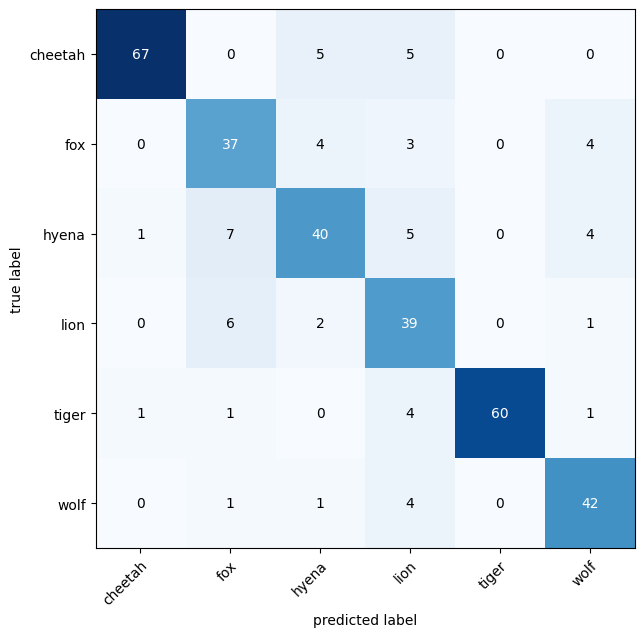

In [25]:
import torch
!pip install torchmetrics mlxtend
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

test_targets = torch.tensor(test_data.dataset.targets)[test_data.indices]

confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
confmat_tensor = confmat(preds=y_pred_tensor.cpu(), target=test_targets)

fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10, 7)
)

In [19]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

test_targets_cpu = test_targets.numpy()
y_pred_cpu = y_pred_tensor.cpu().numpy()

weighted_precision = precision_score(test_targets_cpu, y_pred_cpu, average="weighted")
weighted_recall = recall_score(test_targets_cpu, y_pred_cpu, average="weighted")
weighted_f1 = f1_score(test_targets_cpu, y_pred_cpu, average="weighted")
accuracy = (test_targets_cpu == y_pred_cpu).mean() * 100

print(f"Test Accuracy:      {accuracy:.2f}%")
print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-Score:  {weighted_f1:.4f}\n")

print("Classification Report:")
print(classification_report(test_targets_cpu, y_pred_cpu, target_names=class_names, digits=4))

Test Accuracy:      82.61%
Weighted Precision: 0.8398
Weighted Recall:    0.8261
Weighted F1-Score:  0.8299

Classification Report:
              precision    recall  f1-score   support

     cheetah     0.9710    0.8701    0.9178        77
         fox     0.7115    0.7708    0.7400        48
       hyena     0.7692    0.7018    0.7339        57
        lion     0.6500    0.8125    0.7222        48
       tiger     1.0000    0.8955    0.9449        67
        wolf     0.8077    0.8750    0.8400        48

    accuracy                         0.8261       345
   macro avg     0.8182    0.8210    0.8165       345
weighted avg     0.8398    0.8261    0.8299       345
